In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import math
from scipy import signal
import seaborn as sns
import seaborn as sns
import h5py
from scipy.stats import zscore
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_score, KFold
from matplotlib import cm
from matplotlib.colors import Normalize

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_14324/2699023418.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{int(x_tick / 20000):,}' for x_tick in x_ticks], fontsize=15, fontweight='bold')


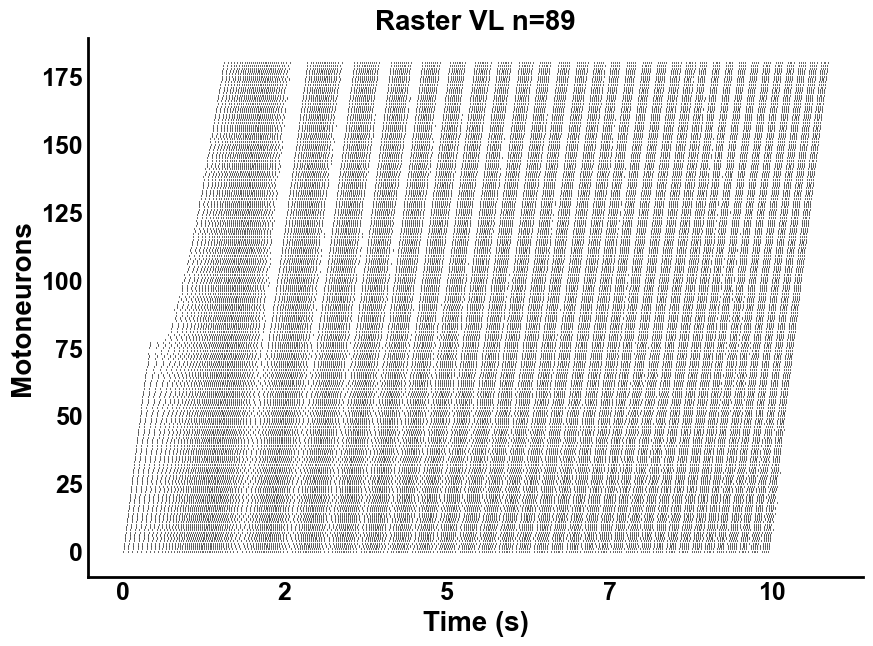

In [57]:
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Spikes/DR_subject1_TAgamma1_chirp_NOPIC.mat"

with h5py.File(file_path, 'r') as f:
    spike_array = f['spike_array'][:]

n_times, n_neurons = spike_array.shape

plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

line_height = 0.5
line_thickness = 0.5

horizontal_offset = 100  # Adjust this value as needed to separate the spikes

# Plot spikes
for neuron in range(n_neurons):
    for t in range(n_times):
        if spike_array[t, neuron] == 1.0:
            # Add a small horizontal offset to each spike for separation
            x_offset = horizontal_offset * neuron
            ax.plot([t + x_offset, t + x_offset], [neuron - line_height / 2, neuron + line_height / 2], 
                    color='black', linewidth=line_thickness)

# Set axis labels
ax.set_xlabel("Time (s)",fontsize=20, fontweight='bold')
ax.set_ylabel("Motoneurons",fontsize=20, fontweight='bold')
ax.set_title("Raster VL n=89",fontsize=20, fontweight='bold')

x_ticks = ax.get_xticks()  # Get current tick locations
ax.set_xticklabels([f'{int(x_tick / 20000):,}' for x_tick in x_ticks], fontsize=15, fontweight='bold')

# Hide grid lines
ax.grid(False)

plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')

# Remove all spines
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

ax.tick_params(axis='both', length=0)

# Save the figure in high quality
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  

# Show the plot
plt.savefig('/Users/nmt121/Desktop/figures/RasterchirpNOPIC.pdf', dpi=300, bbox_inches='tight')



# Show the plot
plt.show()


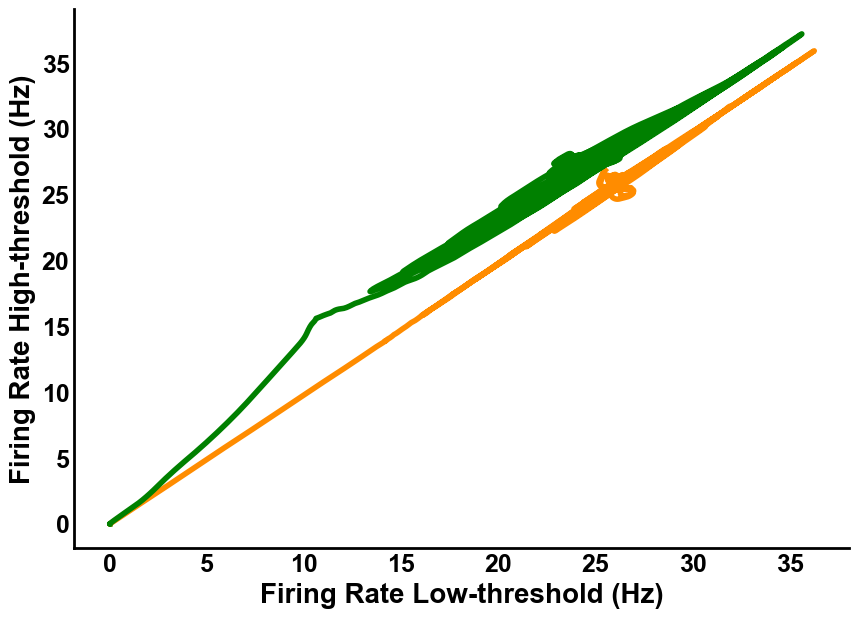

In [64]:
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/pair1314_trajectories_chirp_PICs.jld2"

with h5py.File(file_path, 'r') as f:
    firings_similar = f['trajectory2_controlled'][:].T
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/pair6667_trajectories_chirp_PICs.jld2"

with h5py.File(file_path, 'r') as f:
    firings_diff = f['trajectory2_controlled'][:].T
    

plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))


plt.plot(firings_similar[:,0],firings_similar[:,1],c='darkorange',linewidth=4)
plt.plot(firings_diff[:,0],firings_diff[:,1],c='green',linewidth=4)

# Set axis labels
ax.set_xlabel("Firing Rate Low-threshold (Hz)",fontsize=20, fontweight='bold')
ax.set_ylabel("Firing Rate High-threshold (Hz)",fontsize=20, fontweight='bold')

# Hide grid lines
ax.grid(False)

plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')
# Remove all spines
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

ax.tick_params(axis='both', length=0)

# Save the figure in high quality
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  

# plt.legend(['TA','VL'],fontsize=20)
# Show the plot
plt.savefig('/Users/nmt121/Desktop/figures/firings_fac_PICs_chirp.pdf', dpi=300, bbox_inches='tight')



# Show the plot
plt.show()


In [68]:
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firingsTA_sin_fac_12.jld2"

with h5py.File(file_path, 'r') as f:
    firings_similar = f['trajectory2_controlled'][:].T

firings_similar.shape

(1000, 2)

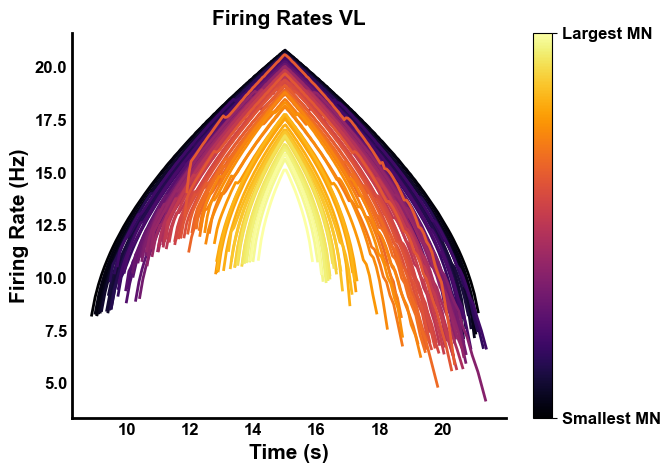

In [16]:
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/allratesVL.jld2"

with h5py.File(file_path, 'r') as f:
    all_rates = f['new_all_rates'][:]

file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/alltimebasesVL.jld2"

with h5py.File(file_path, 'r') as f:
    all_timebases = f['new_all_bases'][:]


# Create a color map using inferno and then discretize it into 87 colors
cmap = plt.get_cmap('inferno')
discrete_cmap = cmap(np.linspace(0, 1, 89))

# Normalize the color range based on the number of motor neurons (87)
norm = Normalize(vmin=0, vmax=88)

# Create a figure and axis
fig, ax = plt.subplots(figsize=(7, 5))

# Plot each firing rate time series with corresponding color
for i in range(89):
    ax.plot(all_timebases[:, i], all_rates[:, i], color=discrete_cmap[i], linewidth=2)

# Set labels and title with Arial font
ax.set_xlabel("Time (s)", fontsize=15, fontweight='bold', fontname='Arial')
ax.set_ylabel("Firing Rate (Hz)", fontsize=15, fontweight='bold', fontname='Arial')
ax.set_title("Firing Rates VL", fontsize=15, fontweight='bold', fontname='Arial')

# Customize ticks with Arial font and remove tick marks
ax.tick_params(axis='both', length=0)
plt.xticks(fontsize=12, fontweight='bold', fontname='Arial')
plt.yticks(fontsize=12, fontweight='bold', fontname='Arial')

# Hide grid lines
ax.grid(False)

# Remove all spines except bottom and left
import seaborn as sns
sns.despine()

# Set the linewidth of the bottom and left spines
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)

# Create the color bar
sm = plt.cm.ScalarMappable(cmap=plt.get_cmap('inferno'), norm=norm)
sm.set_array([])  # The array is just for the color bar, can be left empty

# Add the color bar to the plot
cbar = plt.colorbar(sm, ax=ax)

# Set the color bar ticks to display only two values
cbar.set_ticks([0, 88])
cbar.set_ticklabels(['Smallest MN', 'Largest MN'],fontsize=12, fontweight='bold', fontname='Arial')

# Move the color bar label closer and set the vertical alignment
# cbar.set_label('Motoneuron', fontsize=12, fontweight='bold', fontname='Arial', labelpad=-40)


# Save the figure in high quality
plt.savefig('/Users/nmt121/Desktop/figures/FiringRatesComparisonVL.pdf', dpi=300, bbox_inches='tight')

# Show the plot
plt.show()


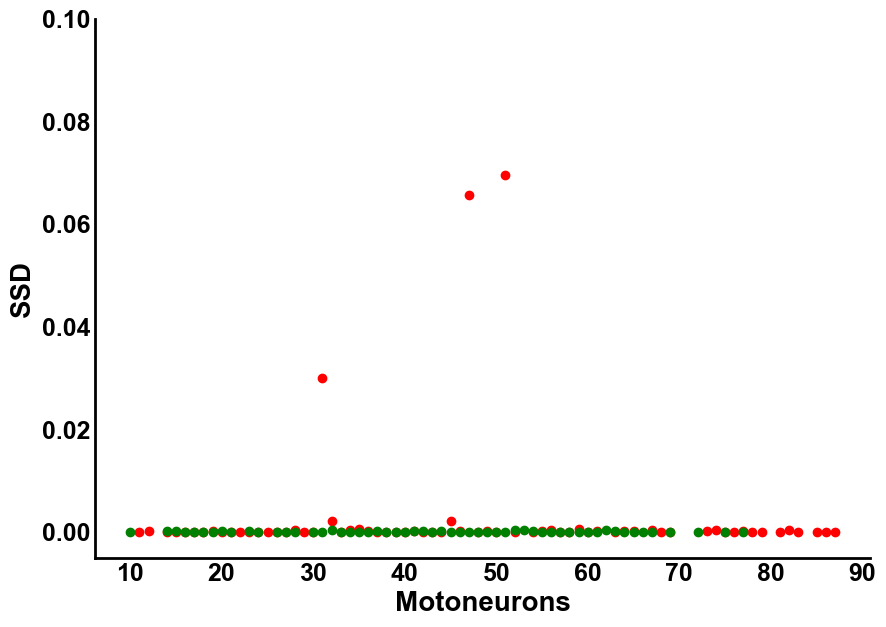

In [4]:
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/accuracy_optim_TA_6sept.jld2"

with h5py.File(file_path, 'r') as f:
    s1 = f['sorted_minimum_values'][:]
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/indices_optim_TA_6sept.jld2"

with h5py.File(file_path, 'r') as f:
    s11 = f['sorted_neuron_indices'][:]
    
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/accuracy_optim_VL_7sept.jld2"

with h5py.File(file_path, 'r') as f:
    s2 = f['sorted_minimum_values'][:]
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/indices_optim_VL_7sept.jld2"

with h5py.File(file_path, 'r') as f:
    s22 = f['sorted_neuron_indices'][:]
    
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

line_height = 0.5
line_thickness = 0.5

plt.scatter(s11,s1,c='red')
plt.scatter(s22,s2,c='green')

# Set axis labels
ax.set_xlabel("Motoneurons",fontsize=20, fontweight='bold')
ax.set_ylabel("SSD",fontsize=20, fontweight='bold')
# ax.set_title("",fontsize=20, fontweight='bold')


# Hide grid lines
ax.grid(False)

plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')
plt.ylim([-0.005,0.1])
# Remove all spines
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

ax.tick_params(axis='both', length=0)

# Save the figure in high quality
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  

# plt.legend(['TA','VL'],fontsize=20)
# Show the plot
plt.savefig('/Users/nmt121/Desktop/figures/Error_Optim_scatter.pdf', dpi=300, bbox_inches='tight')



# Show the plot
plt.show()


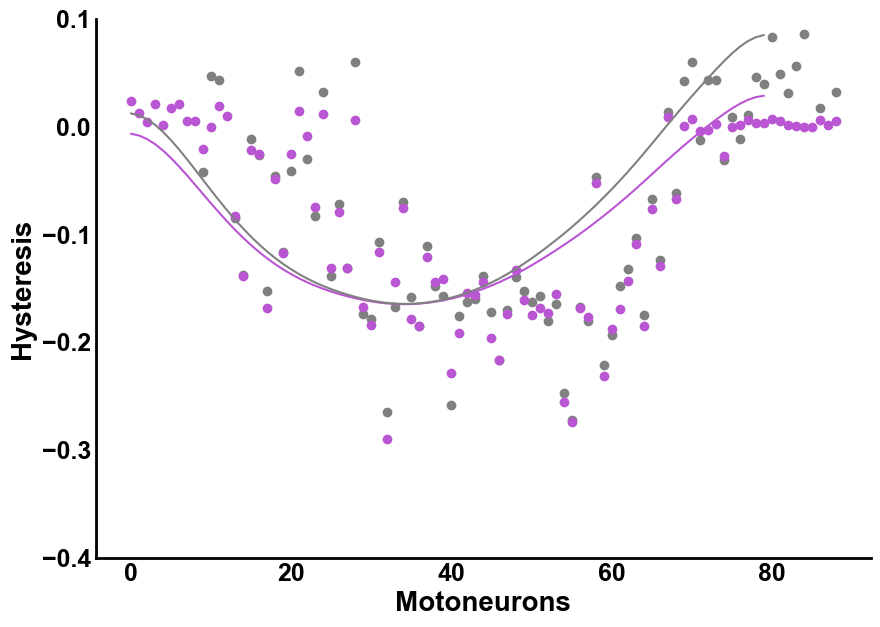

In [147]:


file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/hysteresis_VL_exp.jld2" 

with h5py.File(file_path, 'r') as f:
    exp_hyst = f['hyst_exp'][:]
    


file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/hysteresis_VL.jld2"

with h5py.File(file_path, 'r') as f:
    sim_hyst = f['hysteresis'][:]
    
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/polyfitVL_sim.jld2"

with h5py.File(file_path, 'r') as f:
    polys = f['y_fit_hysteresis_s'][:]
    
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/polyfitVL_exp.jld2"

with h5py.File(file_path, 'r') as f:
    polye = f['y_fit_hysteresis'][:]
    
    
    
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

line_height = 0.5
line_thickness = 0.5

plt.scatter(range(0,89),exp_hyst,c='gray')
plt.scatter(range(0,89),sim_hyst[:,0],c='mediumorchid')
plt.plot(gaussian_filter1d(polys,sigma=4),c='mediumorchid')
plt.plot(gaussian_filter1d(polye,sigma=4),c='gray')

# Set axis labels
ax.set_xlabel("Motoneurons",fontsize=20, fontweight='bold')
ax.set_ylabel("Hysteresis",fontsize=20, fontweight='bold')
# ax.set_title("",fontsize=20, fontweight='bold')


# Hide grid lines
ax.grid(False)

plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')
plt.ylim([-0.005,0.1])
# Remove all spines
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

ax.tick_params(axis='both', length=0)

# Save the figure in high quality
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  
plt.ylim(-0.4,0.1)
# plt.legend(['Experimental','Simulated'],fontsize=15)
# Show the plot
plt.savefig('/Users/nmt121/Desktop/figures/PolyFit_VL_nolegend.png', dpi=300, bbox_inches='tight')



# Show the plot
plt.show()


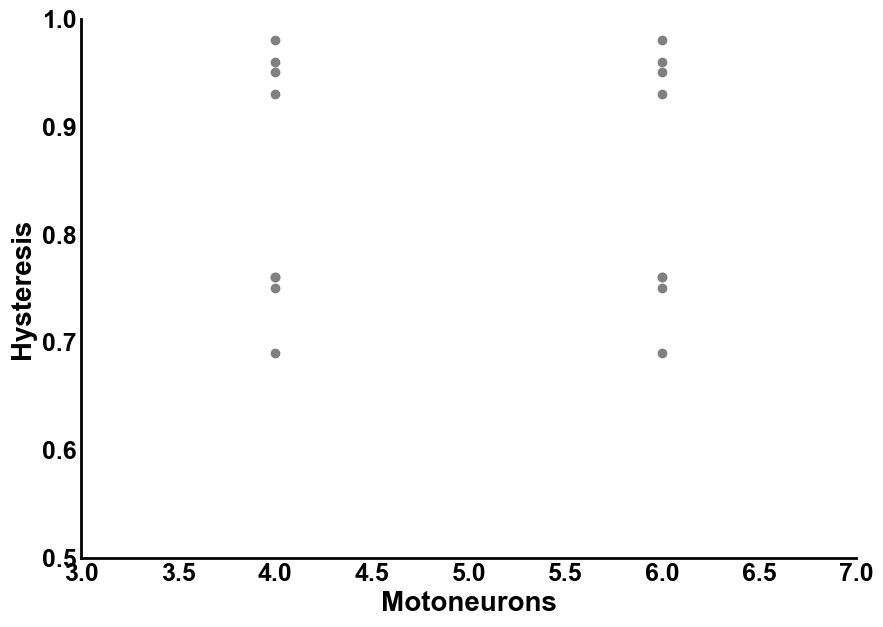

In [49]:
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

line_height = 0.5
line_thickness = 0.5

plt.scatter(np.ones(8)*4,[0.93,0.69,0.76,0.95,0.96,0.75,0.98,0.76],c='gray')
plt.scatter(np.ones(8)*6,[0.93,0.69,0.76,0.95,0.96,0.75,0.98,0.76],c='gray')

# Set axis labels
ax.set_xlabel("Motoneurons",fontsize=20, fontweight='bold')
ax.set_ylabel("Hysteresis",fontsize=20, fontweight='bold')
# ax.set_title("",fontsize=20, fontweight='bold')


# Hide grid lines
ax.grid(False)

plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')
# plt.ylim([-0.005,0.1])
# Remove all spines
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

ax.tick_params(axis='both', length=0)

# Save the figure in high quality
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  
plt.ylim(0.5,1)
plt.xlim(3,7)

# plt.legend(['Experimental','Simulated'],fontsize=15)
# Show the plot
# plt.savefig('/Users/nmt121/Desktop/figures/PolyFit_VL_nolegend.png', dpi=300, bbox_inches='tight')



# Show the plot
plt.show()


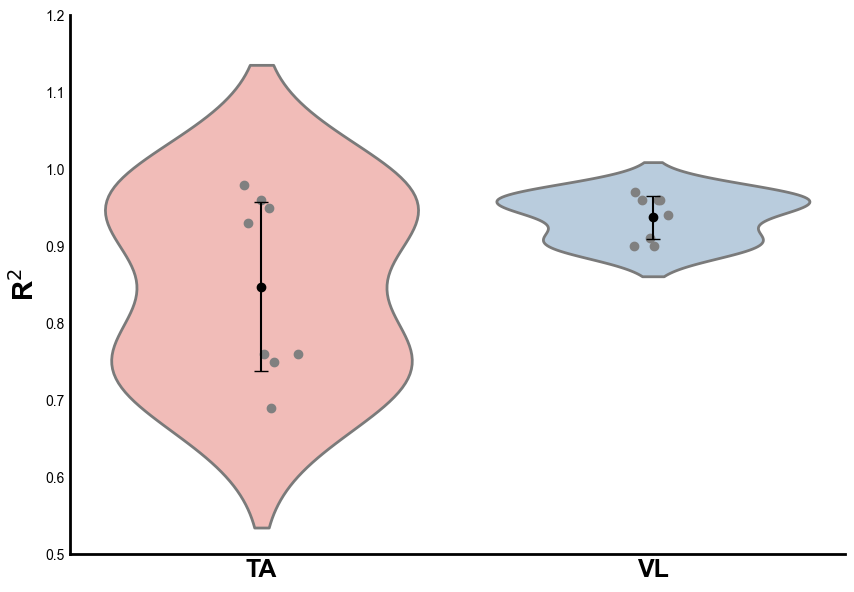

In [77]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data points
group1 = np.array([0.93, 0.69, 0.76, 0.95, 0.96, 0.75, 0.98, 0.76])
group2 = np.array([0.9, 0.94, 0.96, 0.96, 0.96, 0.97, 0.91, 0.9])

# Combine data for violin plot
data = [group1, group2]

# Labels for the groups
labels = ['TA', 'VL']

# Plotting
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

# Create the violin plot
sns.violinplot(data=data, palette='Pastel1', inner=None, linewidth=2)

# Overlay individual data points
for i, group in enumerate(data):
    jittered_x = np.random.normal(i, 0.05, size=len(group))  # Add jitter for better visibility
    plt.scatter(jittered_x, group, color='gray', zorder=10)

# Overlay mean and standard deviation
for i, group in enumerate(data):
    mean = np.mean(group)
    std = np.std(group)
    # Add the mean point
    plt.scatter(i, mean, color='black', zorder=11, label='Mean ± SD' if i == 0 else None)
    # Add the error bar
    plt.errorbar(i, mean, yerr=std, fmt='none', ecolor='black', capsize=5, zorder=10)

# Customize axis labels and appearance
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, fontsize=18, fontweight='bold')
ax.set_ylabel('R$^2$', fontsize=20, fontweight='bold')
# ax.set_xlabel('Motoneurons', fontsize=20, fontweight='bold')

# Hide grid and set line widths
ax.grid(False)
sns.despine()
ax.tick_params(axis='both', length=0)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)

# Set y-limits for better visibility
plt.ylim(0.5, 1.2)

# Show the plot
plt.savefig('/Users/nmt121/Desktop/figures/r2eachsubject.pdf', dpi=300, bbox_inches='tight')
plt.show()


In [66]:
np.mean([0.93, 0.69, 0.76, 0.95, 0.96, 0.75, 0.98, 0.76, 0.9, 0.94, 0.96, 0.96, 0.96, 0.97, 0.91, 0.9])

np.float64(0.8925)

In [ ]:
group1 = np.array([0.93, 0.69, 0.76, 0.95, 0.96, 0.75, 0.98, 0.76])
group2 = np.array([0.9, 0.94, 0.96, 0.96, 0.96, 0.97, 0.91, 0.9])

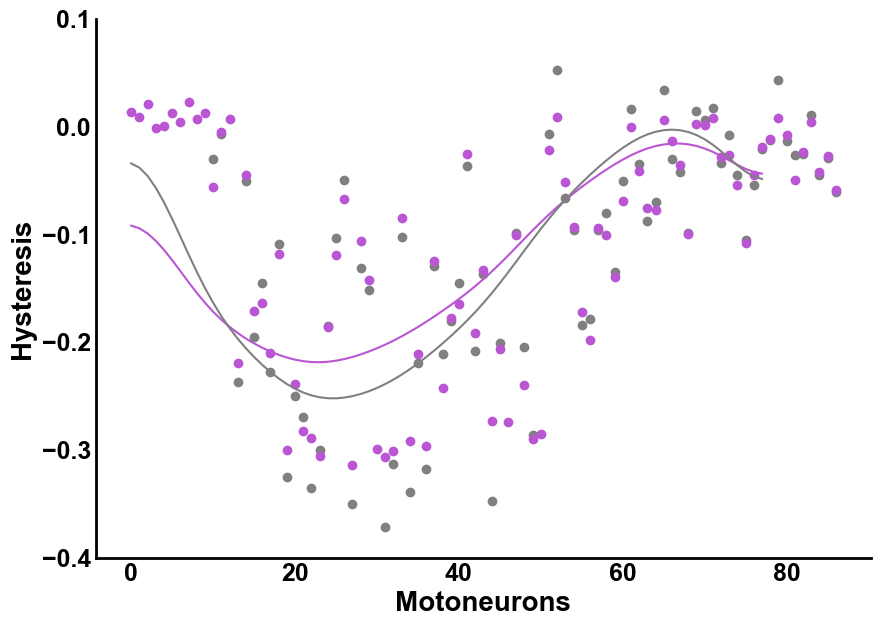

In [40]:


file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/hysteresis_TA_exp.jld2" 

with h5py.File(file_path, 'r') as f:
    exp_hyst = f['hyst_exp'][:]
    


file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/hysteresis_TA.jld2"

with h5py.File(file_path, 'r') as f:
    sim_hyst = f['hysteresis'][:]
    
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/polyfitTA_sim.jld2"

with h5py.File(file_path, 'r') as f:
    polys = f['y_fit_hysteresis_s'][:]
    
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/polyfitTA_exp.jld2"

with h5py.File(file_path, 'r') as f:
    polye = f['y_fit_hysteresis'][:]
    
    
    
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

line_height = 0.5
line_thickness = 0.5

plt.scatter(range(0,87),exp_hyst,c='gray')
plt.scatter(range(0,87),sim_hyst[:,0],c='mediumorchid')
plt.plot(gaussian_filter1d(polys,sigma=4),c='mediumorchid')
plt.plot(gaussian_filter1d(polye,sigma=4),c='gray')

# Set axis labels
ax.set_xlabel("Motoneurons",fontsize=20, fontweight='bold')
ax.set_ylabel("Hysteresis",fontsize=20, fontweight='bold')
# ax.set_title("",fontsize=20, fontweight='bold')


# Hide grid lines
ax.grid(False)

plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')
plt.ylim([-0.005,0.1])
# Remove all spines
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

ax.tick_params(axis='both', length=0)

# Save the figure in high quality
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  
plt.ylim(-0.4,0.1)
# plt.legend(['Experimental','Simulated'],fontsize=15)
# Show the plot
plt.savefig('/Users/nmt121/Desktop/figures/PolyFit_TA_nolegend.pdf', dpi=300, bbox_inches='tight')



# Show the plot
plt.show()

    

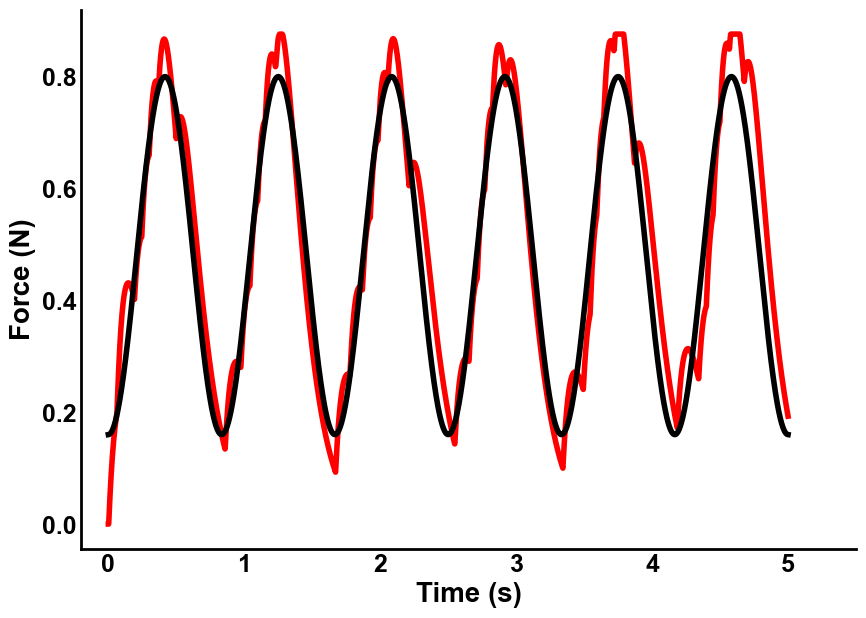

In [50]:
file_path =  "Data_MN_Model/Data_final/Forcetracking/controlled_force.jld2"

with h5py.File(file_path, 'r') as f:
    controlled_force = f['trajectory2_controlled'][:]
    


file_path = "Data_MN_Model/Data_final/Forcetracking/ideal_force.jld2" 

with h5py.File(file_path, 'r') as f:
    ideal_force = f['ideal_force'][:]
    
    
file_path = "Data_MN_Model/Data_final/Forcetracking/newexc.jld2"

with h5py.File(file_path, 'r') as f:
    newexc = f['tr_new'][:]
    
    
file_path = "Data_MN_Model/Data_final/Forcetracking/originalexc.jld2"

with h5py.File(file_path, 'r') as f:
    originalexc = f['tr'][:]
    
    
    
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

line_height = 0.5
line_thickness = 0.5

plt.plot(controlled_force,c='red',linewidth=4)
plt.plot(ideal_force,c='black',linewidth=4)


# Set axis labels
ax.set_xlabel("Time (s)",fontsize=20, fontweight='bold')
ax.set_ylabel("Force (N)",fontsize=20, fontweight='bold')


# Hide grid lines
ax.grid(False)

plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')
# plt.ylim([-0.005,0.1])
# Remove all spines
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

ax.tick_params(axis='both', length=0)

# Save the figure in high quality
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  


ax.set_xticks(ax.get_xticks())  # Explicitly set the ticks
ax.set_xticklabels([f'{int(x_tick / 1000):,}' for x_tick in ax.get_xticks()])  # Set tick labels divided by 20,000

plt.xlim([-200,5500])
plt.savefig('/Users/nmt121/Desktop/figures/forcetracking_sin.png', dpi=300, bbox_inches='tight')



# Show the plot
plt.show()

    

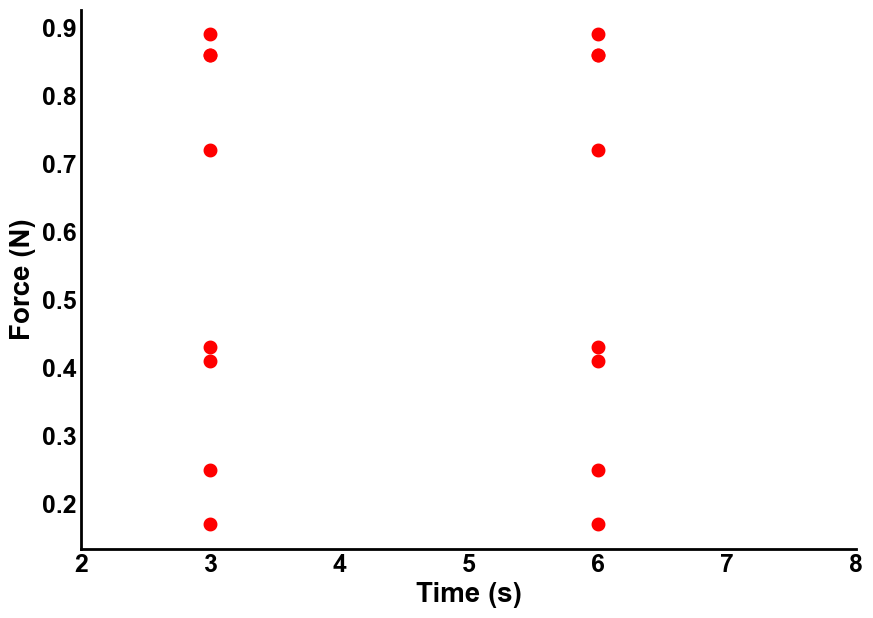

In [36]:
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

line_height = 0.5
line_thickness = 0.5

plt.scatter(np.ones(8)*3,[0.72, 0.25, 0.43, 0.86, 0.86,0.17,0.89,0.41],c='red',linewidth=4)
plt.scatter(np.ones(8)*6,[0.72, 0.25, 0.43, 0.86, 0.86,0.17,0.89,0.41],c='red',linewidth=4)


# Set axis labels
ax.set_xlabel("Time (s)",fontsize=20, fontweight='bold')
ax.set_ylabel("Force (N)",fontsize=20, fontweight='bold')


# Hide grid lines
ax.grid(False)

plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

ax.tick_params(axis='both', length=0)
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  


# ax.set_xticks(ax.get_xticks())  # Explicitly set the ticks
# ax.set_xticklabels([f'{int(x_tick / 1000):,}' for x_tick in ax.get_xticks()])  # Set tick labels divided by 20,000

plt.xlim([2,8])
# plt.savefig('/Users/nmt121/Desktop/figures/forcetracking_sin.png', dpi=300, bbox_inches='tight')



# Show the plot
plt.show()

    

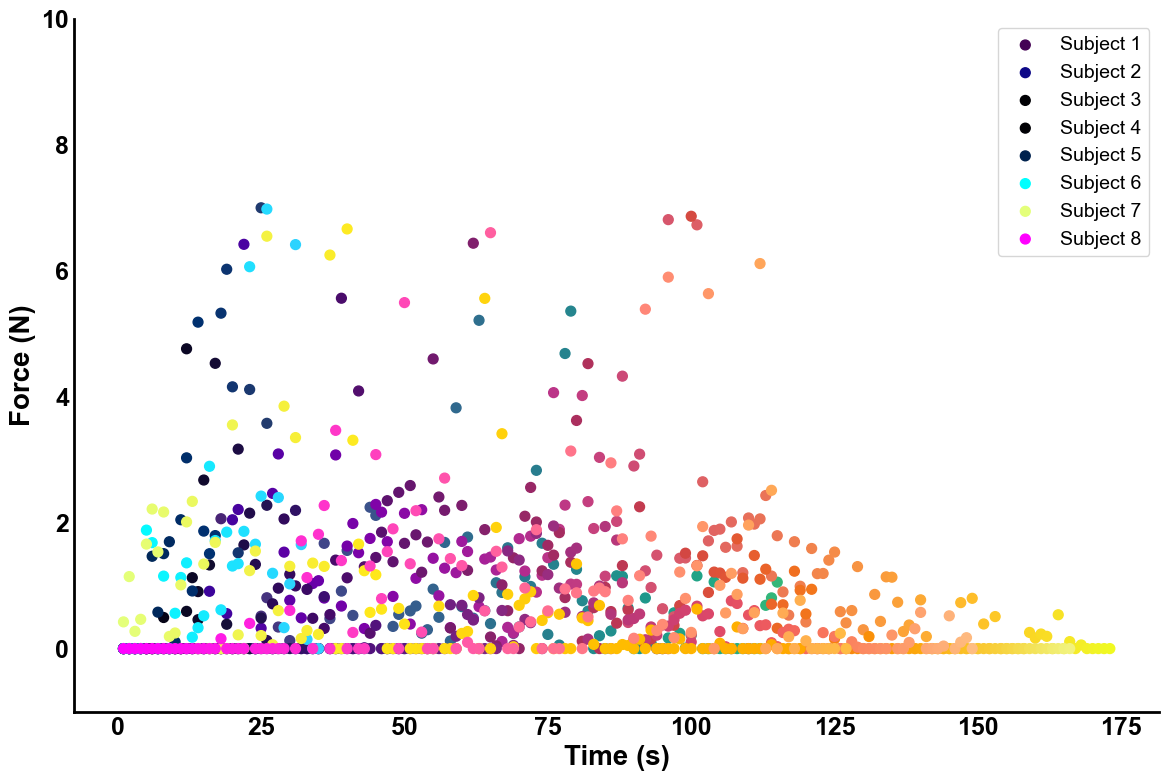

In [24]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm

# Define file paths for each subject
base_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Subjects_optim_process/"
subjects = [f"VthCa_VL_subject{i}_gamma1.jld2" for i in range(1, 9)]

# Load all data into a dictionary
data_dict = {}
max_len = 0

# Load data and determine maximum length
for i, file_name in enumerate(subjects, start=1):
    file_path = f"{base_path}{file_name}"
    with h5py.File(file_path, 'r') as f:
        data = f['VthCa_newVL'][:]
        data_dict[f'subject{i}'] = data[:, 0]
        max_len = max(max_len, len(data[:, 0]))

# Fill shorter arrays with 100
for key in data_dict.keys():
    current_len = len(data_dict[key])
    if current_len < max_len:
        data_dict[key] = np.pad(data_dict[key], (0, max_len - current_len), constant_values=100)

# Plot settings
plt.rcParams['font.family'] = 'Arial'
fig, ax = plt.subplots(figsize=(14, 9))

# Define colormap for each subject
colormaps = [cm.viridis, cm.plasma, cm.inferno, cm.magma, cm.cividis, cm.cool, cm.Wistia, cm.spring]

# Scatter plot for each subject with gradient
for i, (key, colormap) in enumerate(zip(data_dict.keys(), colormaps), start=1):
    x_values = np.arange(1, max_len + 1)
    colors = colormap(np.linspace(0, 1, max_len))
    ax.scatter(x_values, data_dict[key], c=colors, label=f'Subject {i}', s=50)

# Set axis labels and limits
ax.set_xlabel("Time (s)", fontsize=20, fontweight='bold')
ax.set_ylabel("Force (N)", fontsize=20, fontweight='bold')
ax.set_ylim([-1, 10])

# Format the axes
ax.grid(False)
plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')
sns.despine()

ax.tick_params(axis='both', length=0)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)

# Add legend
ax.legend(fontsize=14, loc='upper right')

plt.savefig('/Users/nmt121/Desktop/figures/vthcavalues.pdf', dpi=300, bbox_inches='tight')

# Show the plot
plt.show()


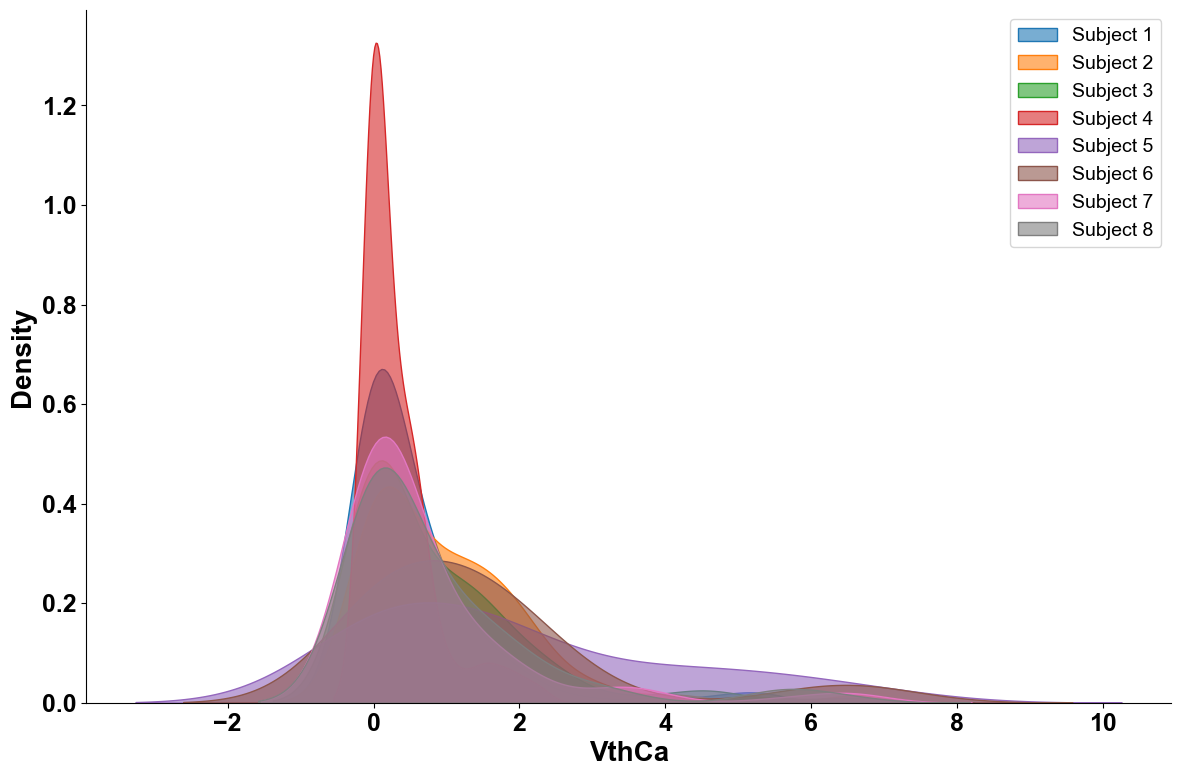

In [15]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define file paths for each subject
base_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Subjects_optim_process/"
subjects = [f"VthCa_VL_subject{i}_gamma1.jld2" for i in range(1, 9)]

# Load all data into a dictionary
data_dict = {}

# Load data
for i, file_name in enumerate(subjects, start=1):
    file_path = f"{base_path}{file_name}"
    with h5py.File(file_path, 'r') as f:
        data = f['VthCa_newVL'][:]
        data_dict[f'subject{i}'] = data[:, 0]

# Plot settings
plt.rcParams['font.family'] = 'Arial'
fig, ax = plt.subplots(figsize=(14, 9))

# Plot distribution for each subject
for i, (key, values) in enumerate(data_dict.items(), start=1):
    sns.kdeplot(values, fill=True, label=f'Subject {i}', alpha=0.6)

# Set axis labels and title
ax.set_xlabel("VthCa", fontsize=20, fontweight='bold')
ax.set_ylabel("Density", fontsize=20, fontweight='bold')
# ax.set_title("Distributions of Force Values for Each Subject", fontsize=22, fontweight='bold')

# Format the axes
plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')
sns.despine()

# Add legend
ax.legend(fontsize=14, loc='upper right')

# Save and show the plot
plt.savefig('/Users/nmt121/Desktop/figures/force_distributions.pdf', dpi=300, bbox_inches='tight')
plt.show()


In [15]:
VthCa_newVL[:,0]


array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 2.06121151, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.51455088,
       0.8068493 , 0.        , 0.34201102, 0.        , 0.12709377,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       1.67062377, 0.47580186, 0.        , 0.91234854, 1.55814933,
       0.52638245, 0.        , 0.        , 2.24319793, 2.11445335,
       0.        , 0.        , 0.3520192 , 0.54318883, 0.        ,
       0.59818564, 0.67545272, 0.2446301 , 0.29943033, 0.94326876,
       0.49720442, 1.68497467, 0.12085664, 3.82162091, 0.66613774,
       1.77012018, 0.48229566, 5.21067309, 0.60202312, 0.39610573,
       1.04512191, 0.8910609 , 1.59972156, 0.24206267, 0.3442933 ,
       1.14020413, 0.98619676, 2.82941645, 1.6722942 , 0.22471

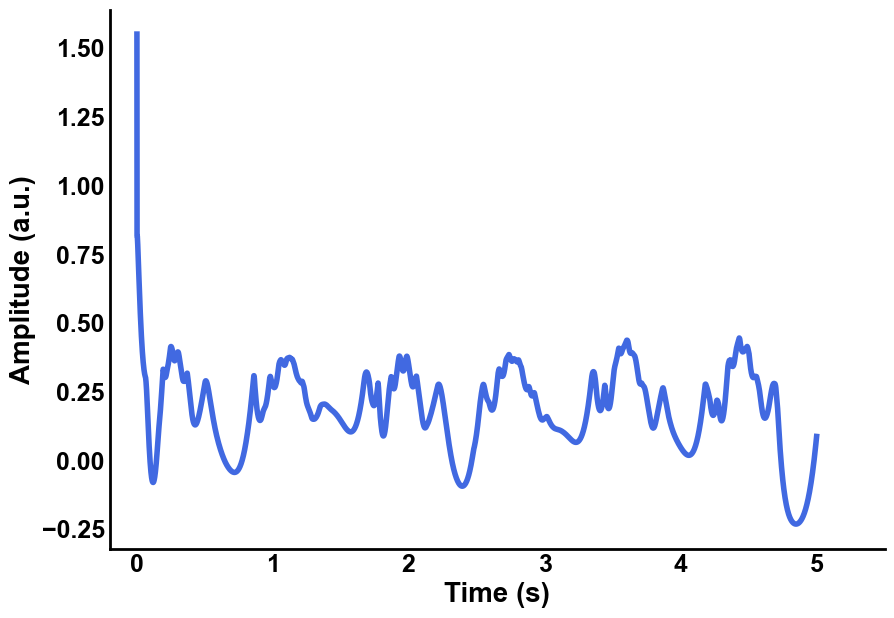

In [117]:
file_path =  "Data_MN_Model/Data_final/Forcetracking/controlled_force.jld2"

with h5py.File(file_path, 'r') as f:
    controlled_force = f['trajectory2_controlled'][:]
    


file_path = "Data_MN_Model/Data_final/Forcetracking/ideal_force.jld2" 

with h5py.File(file_path, 'r') as f:
    ideal_force = f['ideal_force'][:]
    
    
file_path = "Data_MN_Model/Data_final/Forcetracking/newexc.jld2"

with h5py.File(file_path, 'r') as f:
    newexc = f['tr_new'][:]
    
    
file_path = "Data_MN_Model/Data_final/Forcetracking/originalexc.jld2"

with h5py.File(file_path, 'r') as f:
    originalexc = f['tr'][:]
    
    
    
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

line_height = 0.5
line_thickness = 0.5

# plt.plot(originalexc,c='black',linewidth=4)
plt.plot(newexc,c='royalblue',linewidth=4)


# Set axis labels
ax.set_xlabel("Time (s)",fontsize=20, fontweight='bold')
ax.set_ylabel("Amplitude (a.u.)",fontsize=20, fontweight='bold')


# Hide grid lines
ax.grid(False)

plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')
# plt.ylim([-0.005,0.1])
# Remove all spines
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

ax.tick_params(axis='both', length=0)

# Save the figure in high quality
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  


ax.set_xticks(ax.get_xticks())  # Explicitly set the ticks
ax.set_xticklabels([f'{int(x_tick / 1000):,}' for x_tick in ax.get_xticks()])  # Set tick labels divided by 20,000

plt.xlim([-200,5500])
plt.savefig('/Users/nmt121/Desktop/figures/forcetracking_sin_exc.png', dpi=300, bbox_inches='tight')



# Show the plot
plt.show()

    

In [ ]:
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller/TA_4245_changeinh_withstartPIC_2loop/exc_TA_MN42_45_inh_PICstart.jld2"

with h5py.File(file_path, 'r') as f:
    exc1 = f['tr_new'][:]
    

file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller/TA_4245_changeinh_withstartPIC_2loop/force_TA_MN42_45_inh_PICstart.jld2"

with h5py.File(file_path, 'r') as f:
    force = f['force'][:]
    
    
file_path = "Data_MN_Model/Data_final/Controller/TA_4245_changeinh_withstartPIC_2loop/inh_TA_MN42_45_inh_PICstart.jld2"

with h5py.File(file_path, 'r') as f:
    inh = f['inh_input'][:]
    
    
file_path = "Data_MN_Model/Data_final/Controller/TA_4245_changeinh_withstartPIC_2loop/originaltrajectory_TA_MN42_45_inh_PICstart"

with h5py.File(file_path, 'r') as f:
    original = f['trajectory2_controlled'][:]
    
file_path = "Data_MN_Model/Data_final/Controller/TA_4245_changeinh_withstartPIC_2loop/trajectory_controlled_TA_MN42_45_inh_PICstart.jld2"

with h5py.File(file_path, 'r') as f:
    new = f['trajectory2_controlled'][:]
    
    
file_path = "Data_MN_Model/Data_final/Controller/TA_4245_changeinh_withstartPIC_2loop/force_derivative.jld2"

with h5py.File(file_path, 'r') as f:
    force_derivative = f['force_derivative'][:]

In [108]:
downsampled_force = np.mean(force.reshape(-1, 20), axis=1)


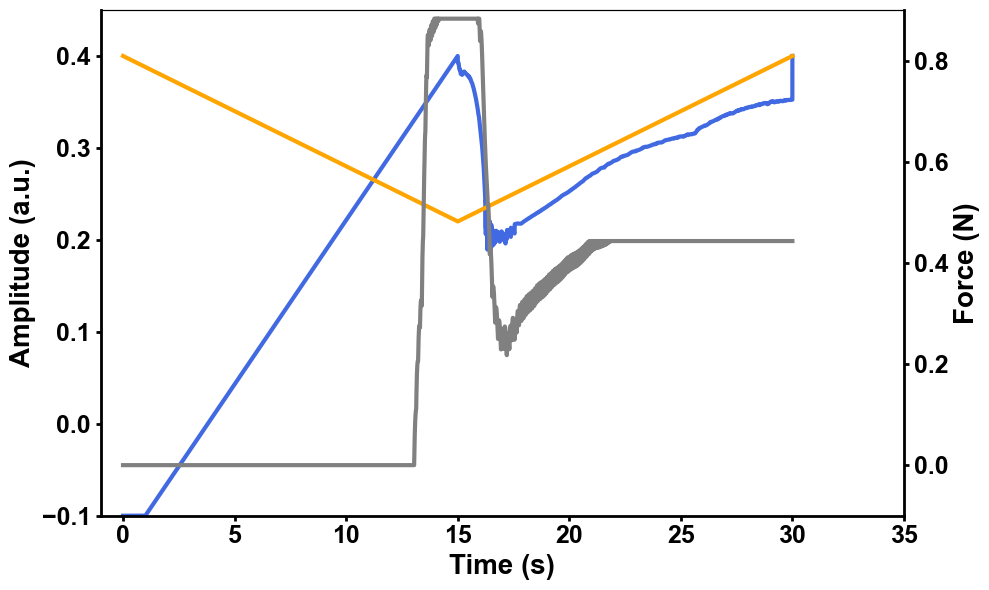

In [171]:
import matplotlib.pyplot as plt
import numpy as np

# Example data (replace with your actual data)
# Create a figure for Excitation, Inhibition, and Force
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot Excitation and Inhibition on the left axis (ax1)
ax1.plot(exc1, label='Excitation', color='royalblue', linewidth=3)
ax1.plot(inh, label='Inhibition', color='orange', linewidth=3)
ax1.set_xlabel("Time (s)", fontsize=20, fontweight='bold')
ax1.set_ylabel("Amplitude (a.u.)", fontsize=20, fontweight='bold')
ax1.tick_params(axis='both', which='major', labelsize=18, width=2, labelcolor='black')

# Set the ticks on the x-axis to show time in seconds
ax1.set_xticks(ax1.get_xticks())
ax1.set_xticklabels([f'{int(x/1000)}' for x in ax1.get_xticks()], fontsize=18, fontweight='bold')

# Set x-axis and y-axis limits for the left axis
ax1.set_xlim(-1000, 35000)
ax1.set_ylim(-0.1, 0.45)

# Create a secondary y-axis for Force (ax2)
ax2 = ax1.twinx()  # This makes ax2 share the same x-axis but have its own y-axis
ax2.plot(downsampled_force, color='gray', label='Force', linewidth=3)
ax2.set_ylabel("Force (N)", fontsize=20, fontweight='bold')
ax2.tick_params(axis='both', which='major', labelsize=18, width=2, labelcolor='black')

# Ensure the force is plotted using the scale of the right y-axis
ax2.spines['right'].set_linewidth(2)
ax2.set_ylim([min(force), max(force)])  # Adjust the y-limits of ax2 based on the force data

# Make axis spines thicker and set tick labels bold for both axes
ax1.spines['bottom'].set_linewidth(2)
ax1.spines['left'].set_linewidth(2)

for tick in ax1.get_xticklabels():
    tick.set_fontsize(18)
    tick.set_fontweight('bold')
for tick in ax1.get_yticklabels():
    tick.set_fontsize(18)
    tick.set_fontweight('bold')
for tick in ax2.get_yticklabels():
    tick.set_fontsize(18)
    tick.set_fontweight('bold')
ax2.set_ylim(-0.1, 0.9)

# Add legends
# ax1.legend(loc='upper left', fontsize=15)
# ax2.legend(loc='upper right', fontsize=15)
plt.savefig('/Users/nmt121/Desktop/figures/4245all.pdf', dpi=300, bbox_inches='tight')

# Adjust layout
plt.tight_layout()

# Show plot
plt.show()


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_47303/901388847.py:46: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('cool', new.shape[1])  # Using binary colormap
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_47303/901388847.py:65: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[0, 1].legend(fontsize=15)


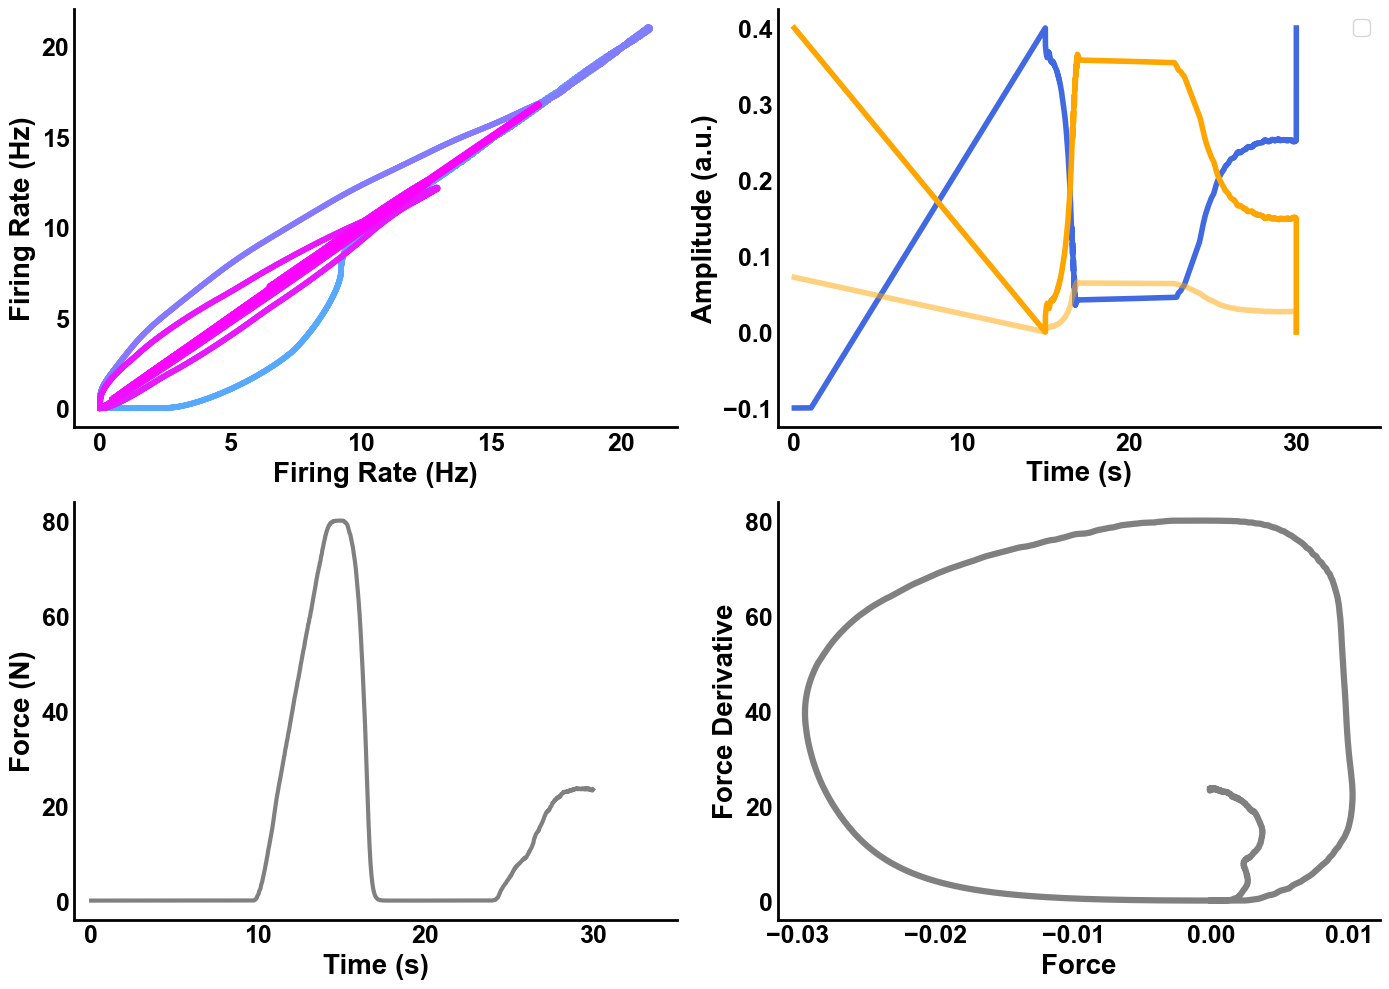

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

file_path = "Data_MN_Model/Data_final/Controller_FINAL_results/exc_TA_MN4551_pushpull.jld2"

with h5py.File(file_path, 'r') as f:
    exc1 = f['tr_new'][:]
    

file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller_FINAL_results/force_TA_MN4551_pushpull.jld2"

with h5py.File(file_path, 'r') as f:
    force = f['force'][:]
    
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller_FINAL_results/inh_TA_MN4551_pushpull.jld2"

with h5py.File(file_path, 'r') as f:
    inh = f['inh_input'][:]
    
    
# file_path = "Data_MN_Model/Data_final/Controller/TA_4245_changeinh_withstartPIC_2loop/originaltrajectory_TA_MN42_45_inh_PICstart"

# with h5py.File(file_path, 'r') as f:
#     original = f['trajectory2_controlled'][:]
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller_FINAL_results/trial.jld2"

with h5py.File(file_path, 'r') as f:
    new = f['trajectory2_controlled'][:]
    
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller_FINAL_results/force_derivative_TA_MN4551_pushpull.jld2"

with h5py.File(file_path, 'r') as f:
    force_derivative = f['force_derivative'][:]
        
    
# Set font to Arial for all plots
plt.rcParams['font.family'] = 'Arial'

# Create a figure with 2x2 subplots
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

cmap = cm.get_cmap('cool', new.shape[1])  # Using binary colormap

# First subplot: New Trajectory with gradient from binary colormap
for i in range(new.shape[1] - 1):
    axs[0, 0].plot(new[0, i:i+2], new[1, i:i+2], color=cmap(i / new.shape[1]), linewidth=4)

axs[0, 0].set_xlabel("Firing Rate (Hz)", fontsize=20, fontweight='bold')
axs[0, 0].set_ylabel("Firing Rate (Hz)", fontsize=20, fontweight='bold')
# axs[0, 0].set_title("Original and New Trajectory", fontsize=22, fontweight='bold')
axs[0, 0].tick_params(axis='both', which='major', labelsize=18, width=2, labelcolor='black', labelrotation=0)
axs[0, 0].grid(False)
axs[0, 0].set_xlim(left=-1)

# Second subplot: Excitation and Inhibition
axs[0, 1].plot(exc1, color='royalblue', linewidth=4)
axs[0, 1].plot(inh*0.18, color='orange', linewidth=4,alpha=0.5)
axs[0, 1].plot(inh, color='orange', linewidth=4)
axs[0, 1].set_xlabel("Time (s)", fontsize=20, fontweight='bold')
axs[0, 1].set_ylabel("Amplitude (a.u.)", fontsize=20, fontweight='bold')
axs[0, 1].legend(fontsize=15)
axs[0, 1].tick_params(axis='both', which='major', labelsize=18, width=2, labelcolor='black')
axs[0, 1].set_xticks(axs[0, 1].get_xticks())
axs[0, 1].set_xticklabels([f'{int(x/1000)}' for x in axs[0, 1].get_xticks()], fontsize=18, fontweight='bold')
axs[0, 1].set_xlim(-1000, 35000)
axs[0, 1].grid(False)

from scipy.ndimage import gaussian_filter1d


# Third subplot: Force
axs[1, 0].plot(force, color='gray', label='Force', linewidth=3)
axs[1, 0].set_xlabel("Time (s)", fontsize=20, fontweight='bold')
axs[1, 0].set_ylabel("Force (N)", fontsize=20, fontweight='bold')
axs[1, 0].tick_params(axis='both', which='major', labelsize=18, width=5, labelcolor='black')
axs[1, 0].set_xticks(axs[1, 0].get_xticks())
axs[1, 0].set_xticklabels([f'{int(x/20000)}' for x in axs[1, 0].get_xticks()], fontsize=18, fontweight='bold')
axs[1, 0].grid(False)
axs[1, 0].set_xlim(-20000, 700000)

# Fourth subplot: Force and Force Derivative (zoomed)
sigma = 8000
smoothed_force_derivative = gaussian_filter1d(force_derivative[0:599999], sigma=sigma)
axs[1, 1].plot(smoothed_force_derivative, force[1:600000],color='gray', linewidth=4.5)
axs[1, 1].set_xlabel("Force", fontsize=20, fontweight='bold')
axs[1, 1].set_ylabel("Force Derivative", fontsize=20, fontweight='bold')
axs[1, 1].tick_params(axis='both', which='major', labelsize=18, width=2, labelcolor='black')
axs[1, 1].grid(False)

# Make axis spines thicker and set tick labels bold for all subplots
for ax in axs.flat:
    ax.spines['bottom'].set_linewidth(2)
    ax.spines['left'].set_linewidth(2)
    ax.tick_params(axis='both', which='both', length=0)  # Remove ticks
    for tick in ax.get_xticklabels():
        tick.set_fontsize(18)
        tick.set_fontweight('bold')
    for tick in ax.get_yticklabels():
        tick.set_fontsize(18)
        tick.set_fontweight('bold')

# Adjust layout and appearance
plt.tight_layout()
sns.despine()
plt.savefig('/Users/nmt121/Desktop/trial.pdf', dpi=300, bbox_inches='tight')

# Show plot
plt.show()

In [20]:
sigma = 5
smoothed_force_derivative = gaussian_filter1d(force_derivative[1:599999], sigma=sigma)
smoothed_force_derivative.shape

(599998,)

NameError: name 'G' is not defined

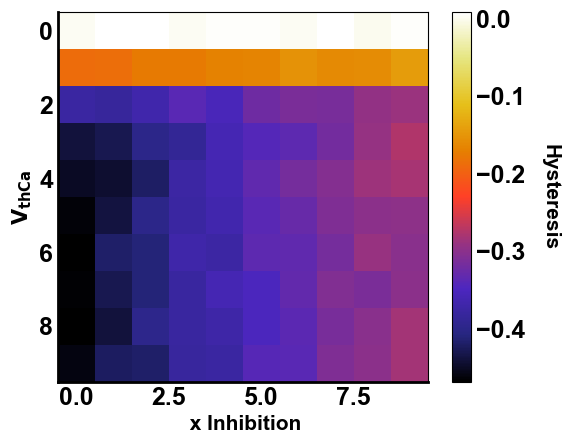

In [63]:
import matplotlib.pyplot as plt
import h5py

# Load the hysteresis data from the .jld2 file
file_path = "Data_MN_Model/Heatmap_values/hysteresis_heatmap5_constant_gamma1.jld2"
with h5py.File(file_path, 'r') as f:
    hyst = f['hysteresis_for_each_inh'][:].T

# Set font to Arial and apply consistent styling
plt.rcParams['font.family'] = 'Arial'

# Create the heatmap plot with the CMRmap colormap
plt.imshow(hyst, cmap='CMRmap')

# Set the x and y labels with the same font size and weight as before
plt.xlabel(" x Inhibition", fontsize=15, fontweight='bold')
plt.ylabel(r"$\mathbf{V_{thCa}}$", fontsize=15)

# Add a colorbar and customize its font size
cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=18)

# Set colorbar tick labels to bold
for tick in cbar.ax.get_yticklabels():
    tick.set_fontweight('bold')

# Customize tick parameters (font size, width, color, and fontweight for bold numbers)
plt.tick_params(axis='both', which='major', labelsize=18, width=2, labelcolor='black')

# Manually set the fontweight of the tick labels to bold
ax = plt.gca()  # Get current axis
for tick in ax.get_xticklabels():
    tick.set_fontweight('bold')
for tick in ax.get_yticklabels():
    tick.set_fontweight('bold')

# Make axis spines thicker for consistency
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.tick_params(axis='both', which='both', length=0)

# Disable grid to match previous plots
plt.grid(False)

# Display the plot
cbar.set_label('Hysteresis', fontsize=15, fontweight='bold', fontname='Arial', rotation=270, labelpad=25)
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)
cbar.ax.tick_params(size=0)  # Set tick size to 0 to remove the small lines

plt.savefig('/Users/nmt121/Desktop/figures/HeatmapMN5_constant_gamma1.pdf', dpi=300, bbox_inches='tight')


# Display the plot
plt.show()



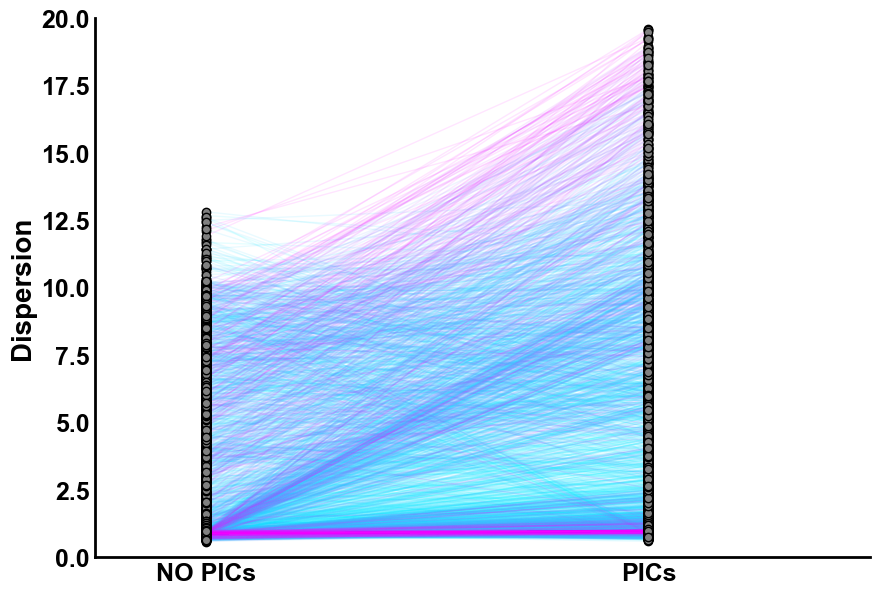

In [151]:
import scipy.io
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data
file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/dispersion_sinusoid_NOPIC.mat"
mat_data = scipy.io.loadmat(file_path)
dispersion_NOPIC = mat_data['dispersion'][0,:]

file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/dispersion_sinusoid_PIC.mat"
mat_data = scipy.io.loadmat(file_path)
dispersion_PIC = mat_data['dispersion'][0,:]

file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/vthca_sinusoid_PIC_trial2.mat"
mat_data = scipy.io.loadmat(file_path)
biophysical_properties = mat_data['different_biophysical_properties'][0,:]

norm = plt.Normalize(vmin=np.min(np.abs(biophysical_properties)), vmax=np.max(np.abs(biophysical_properties)))

# Set plot settings
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))
cmap = plt.cm.cool

# Draw transparent lines between the corresponding points in PIC and NOPIC first
for i in range(len(dispersion_PIC)):
    color = cmap(norm(abs(biophysical_properties[i])))  # Map the biophysical property to a color
    plt.plot([2, 6], [dispersion_NOPIC[i], dispersion_PIC[i]], color=color, linewidth=1.5, alpha=0.1)  # Line with gradient color

# sorted_indices = np.argsort(abs(biophysical_properties))
# for i in sorted_indices:
#     color = cmap(norm(abs(biophysical_properties[i])))  # Map the biophysical property to a color
    
#     # Plot the lines after sorting, so higher values (more pink) are plotted last
#     plt.plot([2, 6], [dispersion_NOPIC[i], dispersion_PIC[i]], color=color, linewidth=1, alpha=0.1)


# Now plot the scatter plot for PIC and NOPIC after drawing the lines
plt.scatter(np.ones(len(dispersion_NOPIC))*2, dispersion_NOPIC, c='grey', edgecolors='black', zorder=3, label='PIC')
plt.scatter(np.ones(len(dispersion_NOPIC))*6, dispersion_PIC, c='grey', edgecolors='black', zorder=3, label='NOPIC')

# Set axis labels
ax.set_ylabel("Dispersion", fontsize=20, fontweight='bold')

# Customize x-ticks to show "NOPIC" and "PIC"
plt.xticks([2, 6], ['NO PICs', 'PICs'], fontsize=18, fontweight='bold')  # Customize x-tick labels
plt.yticks(fontsize=18, fontweight='bold')
plt.ylim([0, 20])
plt.xlim([1, 8])

# Hide grid lines
ax.grid(False)

# Remove all spines except bottom and left
sns.despine()
ax.tick_params(axis='both', which='both', length=0)

# Customize axis line thickness
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)

plt.savefig('/Users/nmt121/Desktop/figures/dispersion_sin.png', dpi=300, bbox_inches='tight')


# Display the plot
plt.show()




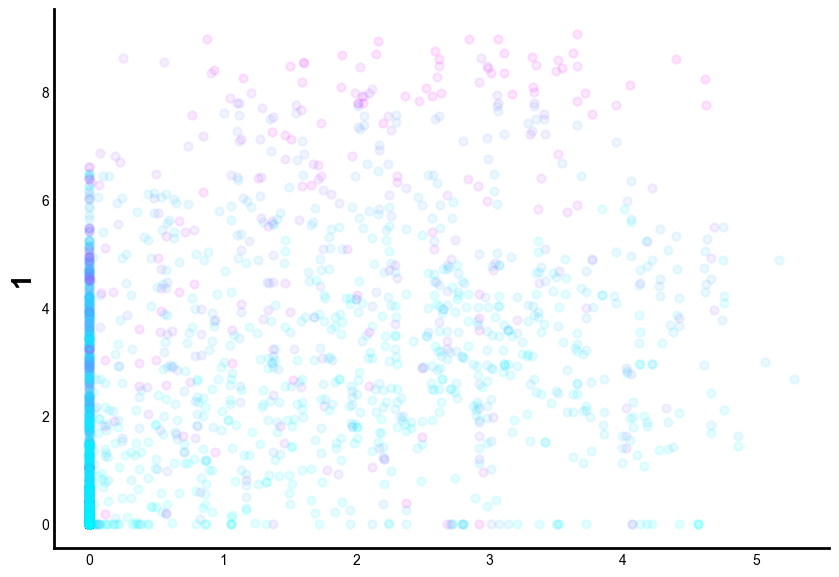

In [21]:
import scipy.io
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data
file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/displacement_sinusoid_NOPIC.mat"
mat_data = scipy.io.loadmat(file_path)
displacement_NOPIC = mat_data['displacement'][0,:]

file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/displacement_sinusoid_PIC.mat"
mat_data = scipy.io.loadmat(file_path)
displacement_PIC = mat_data['displacement'][0,:]

file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/vthca_sinusoid_PIC_trial2.mat"
mat_data = scipy.io.loadmat(file_path)
biophysical_properties = mat_data['different_biophysical_properties'][0,:]

norm = plt.Normalize(vmin=np.min(np.abs(biophysical_properties)), vmax=np.max(np.abs(biophysical_properties)))

# Set plot settings
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))
cmap = plt.cm.cool

# Draw transparent lines between the corresponding points in PIC and NOPIC first
for i in range(len(dispersion_PIC)):
    color = cmap(norm(abs(biophysical_properties[i])))  # Map the biophysical property to a color
    plt.scatter(dispersion_NOPIC[i], dispersion_PIC[i], color=color, linewidth=1.5, alpha=0.1)  # Line with gradient color



# Set axis labels
ax.set_ylabel("1", fontsize=20, fontweight='bold')

# Customize x-ticks to show "NOPIC" and "PIC"
# plt.xticks([2, 6], ['NO PICs', 'PICs'], fontsize=18, fontweight='bold')  # Customize x-tick labels
# plt.yticks(fontsize=18, fontweight='bold')
# plt.ylim([0, 20])
# plt.xlim([1, 8])

# Hide grid lines
ax.grid(False)

# Remove all spines except bottom and left
sns.despine()
ax.tick_params(axis='both', which='both', length=0)

# Customize axis line thickness
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)

# plt.savefig('/Users/nmt121/Desktop/figures/dispersion_sin.png', dpi=300, bbox_inches='tight')


# Display the plot
# plt.show()




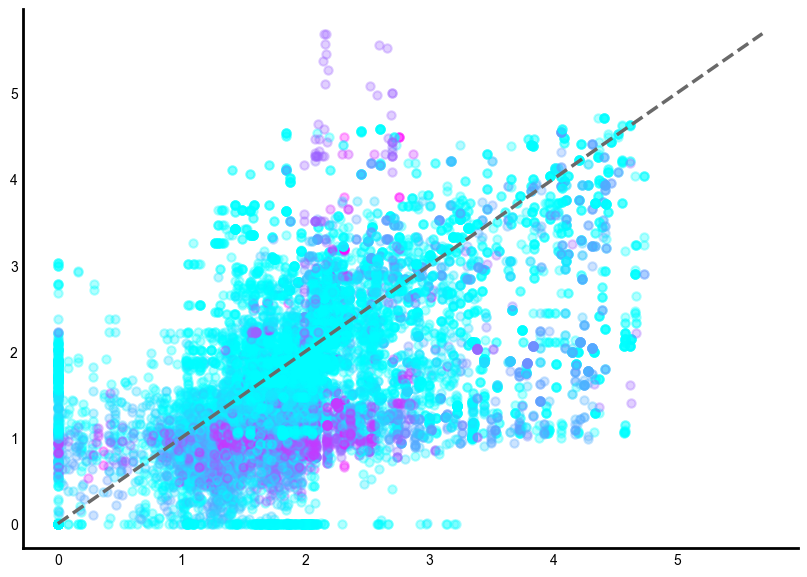

In [60]:

import scipy.io
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/displacemnet_chirp_NOPIC3.mat"
mat_data = scipy.io.loadmat(file_path)
displacement_NOPIC = mat_data['displacement'][0,:]

file_path ="/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/displacemnet_chirp_PIC3.mat"
mat_data = scipy.io.loadmat(file_path)
displacement_PIC = mat_data['displacement'][0,:]



# file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/dispersion_chirp_NOPIC3.mat"
# mat_data = scipy.io.loadmat(file_path)
# dispersion_NOPIC = mat_data['dispersion'][0,:]

# file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/dispersion_chirp_PIC3.mat"
# mat_data = scipy.io.loadmat(file_path)
# dispersion_PIC = mat_data['dispersion'][0,:]

file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/vthca_sinusoid_PIC_trial3.mat"
mat_data = scipy.io.loadmat(file_path)
biophysical_properties = mat_data['different_biophysical_properties'][0,:]
norm = plt.Normalize(vmin=np.min(np.abs(biophysical_properties)), vmax=np.max(np.abs(biophysical_properties)))

max_val = max(np.max(displacement_PIC), np.max(displacement_NOPIC))
min_val = min(np.min(displacement_PIC), np.min(displacement_NOPIC))
fig, ax = plt.subplots(figsize=(10, 7))

plt.plot([min_val, max_val], [min_val, max_val], '--',color='dimgray',label='Diagonal (y = x)', linewidth=2.5)

cmap = plt.cm.cool

# Draw transparent lines between the corresponding points in PIC and NOPIC first
for i in range(len(displacement_PIC)):
    color = cmap(norm(abs(biophysical_properties[i])))  # Map the biophysical property to a color
    plt.scatter(displacement_NOPIC[i], displacement_PIC[i], color=color, linewidth=1.5, alpha=0.3)  # Line with gradient color



# Hide grid lines
ax.grid(False)

# Remove all spines except bottom and left
sns.despine()
ax.tick_params(axis='both', which='both', length=0)

# Customize axis line thickness
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)



plt.savefig('/Users/nmt121/Desktop/figures/scatter_displ_chirp_final.pdf', dpi=300, bbox_inches='tight')




In [47]:
len(biophysical_properties)

3741

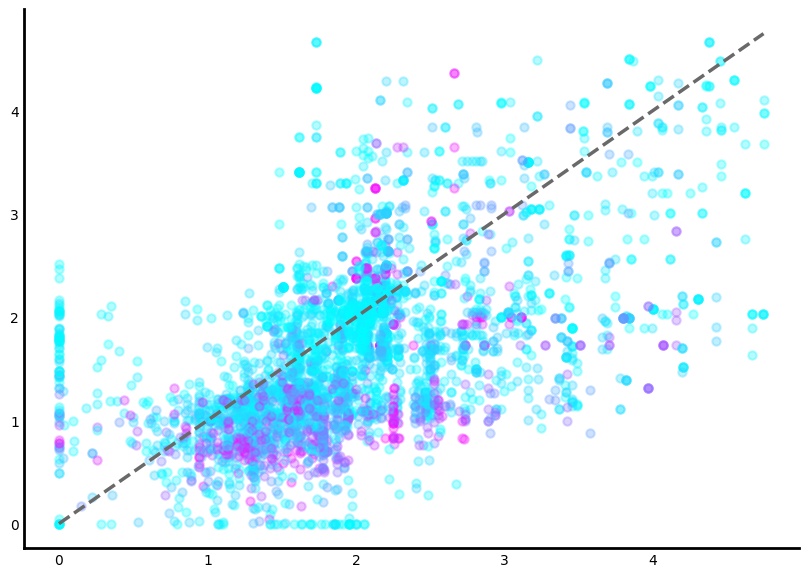

In [9]:
# file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/displacement_sinusoid_NOPIC.mat"
# mat_data = scipy.io.loadmat(file_path)
# displacement_NOPIC = mat_data['displacement'][0,:]

# file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/displacement_sinusoid_PIC.mat"
# mat_data = scipy.io.loadmat(file_path)
# displacement_PIC = mat_data['displacement'][0,:]

import scipy.io
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/displacement_chirp_NOPIC.mat"
mat_data = scipy.io.loadmat(file_path)
displacement_NOPIC = mat_data['displacement'][0,:]

file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/displacement_chirp_PIC.mat"
mat_data = scipy.io.loadmat(file_path)
displacement_PIC = mat_data['displacement'][0,:]

file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/vthca_sinusoid_PIC_trial2.mat"
mat_data = scipy.io.loadmat(file_path)
biophysical_properties = mat_data['different_biophysical_properties'][0,:]
norm = plt.Normalize(vmin=np.min(np.abs(biophysical_properties)), vmax=np.max(np.abs(biophysical_properties)))

max_val = max(np.max(displacement_PIC), np.max(displacement_NOPIC))
min_val = min(np.min(displacement_PIC), np.min(displacement_NOPIC))
fig, ax = plt.subplots(figsize=(10, 7))

plt.plot([min_val, max_val], [min_val, max_val], '--',color='dimgray',label='Diagonal (y = x)', linewidth=2.5)

cmap = plt.cm.cool

# Draw transparent lines between the corresponding points in PIC and NOPIC first
for i in range(len(dispersion_PIC)):
    color = cmap(norm(abs(biophysical_properties[i])))  # Map the biophysical property to a color
    plt.scatter(displacement_NOPIC[i], displacement_PIC[i], color=color, linewidth=1.5, alpha=0.3)  # Line with gradient color



# Hide grid lines
ax.grid(False)

# Remove all spines except bottom and left
sns.despine()
ax.tick_params(axis='both', which='both', length=0)

# Customize axis line thickness
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)



plt.savefig('/Users/nmt121/Desktop/figures/scatter_displacement_chirp.pdf', dpi=300, bbox_inches='tight')




In [162]:
max_val = max(np.max(dispersion_PIC), np.max(dispersion_NOPIC))
min_val = min(np.min(dispersion_PIC), np.min(dispersion_NOPIC))

In [159]:
dispersion_PIC[1]

np.float64(2.405030485855816)

In [130]:
file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/vthca_sinusoid_PIC_trial2.mat"
mat_data = scipy.io.loadmat(file_path)
biophysical_properties = mat_data['different_biophysical_properties'][0,:]


np.float64(0.0)

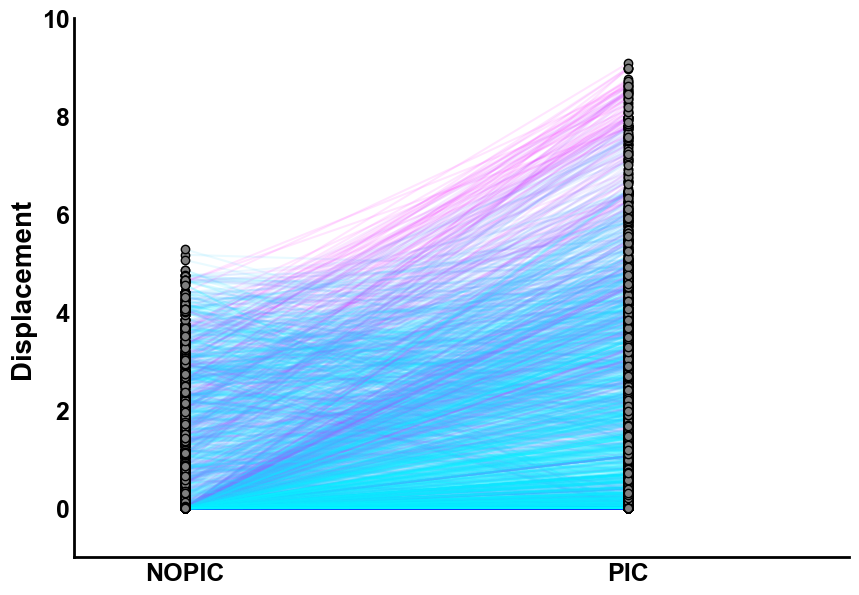

In [145]:
# Load the data
file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/displacement_sinusoid_NOPIC.mat"
mat_data = scipy.io.loadmat(file_path)
displacement_NOPIC = mat_data['displacement'][0,:]

file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/displacement_sinusoid_PIC.mat"
mat_data = scipy.io.loadmat(file_path)
displacement_PIC = mat_data['displacement'][0,:]

# Set plot settings
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

norm = plt.Normalize(vmin=np.min(np.abs(biophysical_properties)), vmax=np.max(np.abs(biophysical_properties)))

# Set plot settings
plt.rcParams['font.family'] = 'Arial'

cmap = plt.cm.cool

# Draw transparent lines between the corresponding points in PIC and NOPIC first
for i in range(len(dispersion_PIC)):
    color = cmap(norm(abs(biophysical_properties[i])))  # Map the biophysical property to a color
    plt.plot([2, 6], [displacement_NOPIC[i], displacement_PIC[i]], color=color, linewidth=1.5, alpha=0.1)  # Line with gradient color



# Now plot the scatter plot for PIC and NOPIC after drawing the lines
plt.scatter(np.ones(len(displacement_NOPIC))*2, displacement_NOPIC, c='grey', edgecolors='black', zorder=3, label='PIC')
plt.scatter(np.ones(len(displacement_PIC))*6, displacement_PIC, c='grey', edgecolors='black', zorder=3, label='NOPIC')

# Set axis labels
ax.set_ylabel("Displacement", fontsize=20, fontweight='bold')

# Customize x-ticks to show "NOPIC" and "PIC"
plt.xticks([2, 6], ['NOPIC', 'PIC'], fontsize=18, fontweight='bold')  # Customize x-tick labels
plt.yticks(fontsize=18, fontweight='bold')
plt.ylim([-1, 10])
plt.xlim([1, 8])

# Hide grid lines
ax.grid(False)

# Remove all spines except bottom and left
sns.despine()

# Customize axis line thickness
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)
ax.tick_params(axis='both', which='both', length=0)

plt.savefig('/Users/nmt121/Desktop/figures/displacement_sin.png', dpi=300, bbox_inches='tight')

# Display the plot
plt.show()


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_6937/3601837442.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{int(x_tick / 20000):,}' for x_tick in x_ticks], fontsize=15, fontweight='bold')


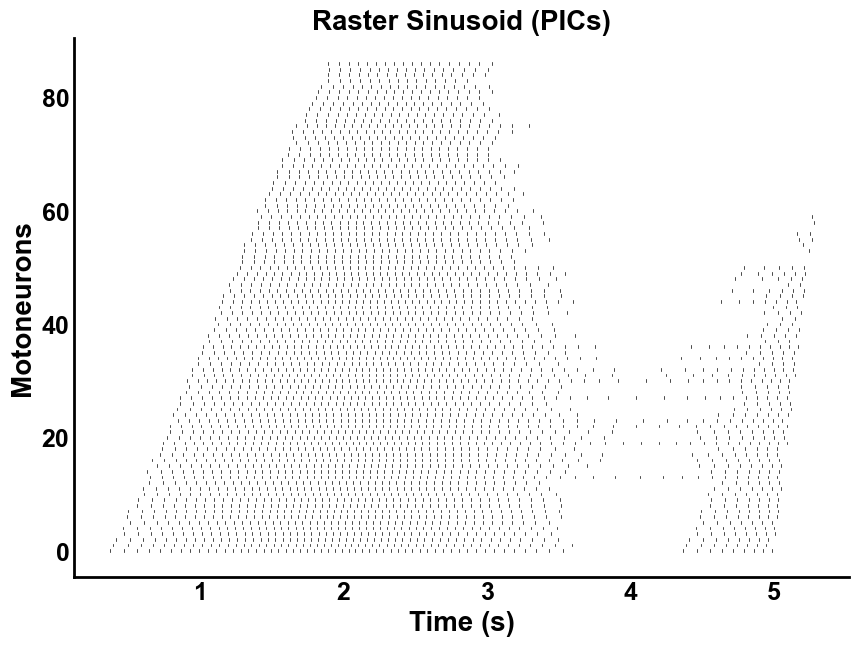

In [149]:
file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/DR_Sinusoid_025.mat"

with h5py.File(file_path, 'r') as f:
    spike_array = f['spike_array'][:]

n_times, n_neurons = spike_array.shape

plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

line_height = 0.5
line_thickness = 0.5

horizontal_offset = 100  # Adjust this value as needed to separate the spikes

# Plot spikes
for neuron in range(n_neurons):
    for t in range(n_times):
        if spike_array[t, neuron] == 1.0:
            # Add a small horizontal offset to each spike for separation
            x_offset = horizontal_offset * neuron
            ax.plot([t + x_offset, t + x_offset], [neuron - line_height / 2, neuron + line_height / 2], 
                    color='black', linewidth=line_thickness)

# Set axis labels
ax.set_xlabel("Time (s)",fontsize=20, fontweight='bold')
ax.set_ylabel("Motoneurons",fontsize=20, fontweight='bold')
ax.set_title("Raster Sinusoid (PICs)",fontsize=20, fontweight='bold')

x_ticks = ax.get_xticks()  # Get current tick locations
ax.set_xticklabels([f'{int(x_tick / 20000):,}' for x_tick in x_ticks], fontsize=15, fontweight='bold')

# Hide grid lines
ax.grid(False)

plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')

# Remove all spines
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

ax.tick_params(axis='both', length=0)

# Save the figure in high quality
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  

# Show the plot
plt.savefig('/Users/nmt121/Desktop/figures/RasterSinusoid_PIC_TA.png', dpi=300, bbox_inches='tight')



# Show the plot
plt.show()


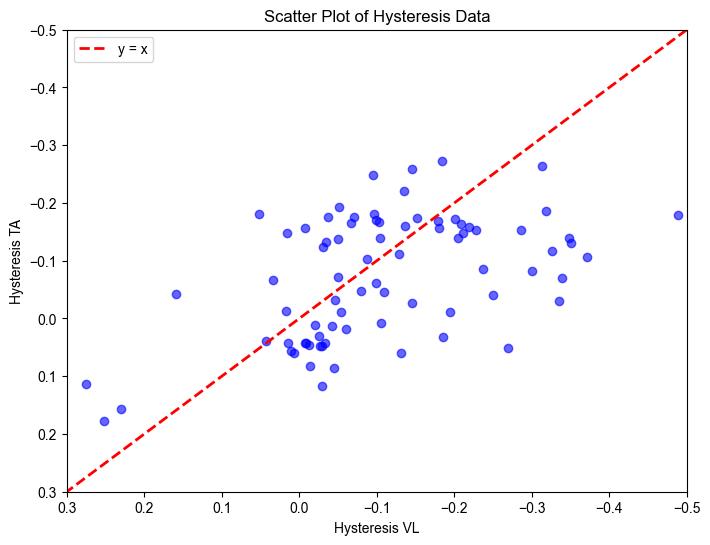

In [34]:
import h5py
import matplotlib.pyplot as plt
import numpy as np

# Define file paths
file_ta = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/hysteresis_TA_exp.jld2"
file_vl = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/hysteresis_exp_VL.jld2"

# Function to load data from a JLD2 file
def load_jld2_data(filepath):
    with h5py.File(filepath, 'r') as f:
        key = list(f.keys())[0]  # Get the first dataset key
        data = f[key][()]  # Extract the data
    return data

# Load data
ta_data = load_jld2_data(file_ta)
vl_data = load_jld2_data(file_vl)

# Ensure both datasets are of the same length
min_length = min(len(ta_data), len(vl_data))
ta_data = ta_data[:min_length]
vl_data = vl_data[:min_length]

# Scatter plot
plt.figure(figsize=(8, 6))
plt.ylim([0.3, -0.5])  # Reversed limits for y-axis
plt.xlim([0.3,-0.5])  # Reversed limits for x-axis
plt.scatter(ta_data, vl_data, marker='o', color='b', alpha=0.6)

# Diagonal line (y = x)
x_vals = np.linspace(-0.5, 0.3, 100)  # Define x values
plt.plot(x_vals, x_vals, 'r--', linewidth=2, label="y = x")  # Red dashed line

plt.xlabel("Hysteresis VL")
plt.ylabel("Hysteresis TA")
plt.title("Scatter Plot of Hysteresis Data")
plt.legend()  # Show legend for the diagonal line

plt.savefig('/Users/nmt121/Desktop/figures/hystbinned.pdf', dpi=300, bbox_inches='tight')

plt.show()


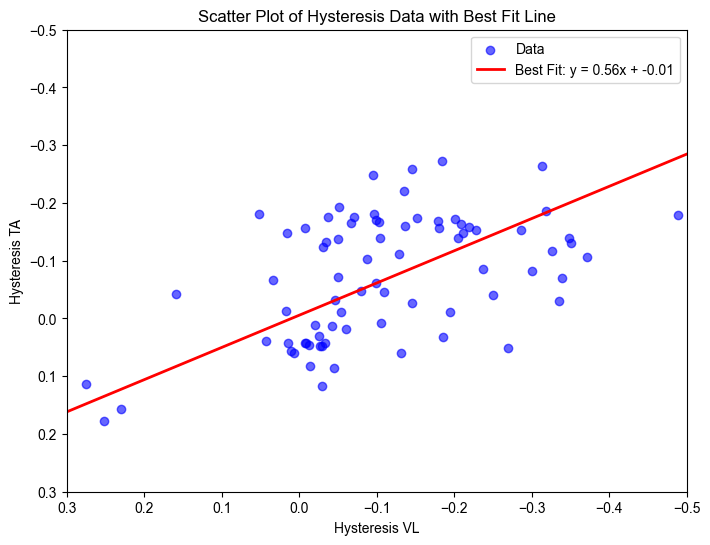

In [37]:
import h5py
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress

# Define file paths
file_ta = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/hysteresis_TA_exp.jld2"
file_vl = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/hysteresis_exp_VL.jld2"

# Function to load data from a JLD2 file
def load_jld2_data(filepath):
    with h5py.File(filepath, 'r') as f:
        key = list(f.keys())[0]  # Get the first dataset key
        data = f[key][()]  # Extract the data
    return data

# Load data
ta_data = load_jld2_data(file_ta)
vl_data = load_jld2_data(file_vl)

# Ensure both datasets are of the same length
min_length = min(len(ta_data), len(vl_data))
ta_data = ta_data[:min_length]
vl_data = vl_data[:min_length]

# Fit a regression line
slope, intercept, _, _, _ = linregress(ta_data, vl_data)

# Generate line points
x_vals = np.linspace(min(ta_data), max(ta_data), 100)
y_vals = slope * x_vals + intercept

# Scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(ta_data, vl_data, marker='o', color='b', alpha=0.6, label="Data")

# Best-fit line
plt.plot(x_vals, y_vals, 'r-', linewidth=2, label=f"Best Fit: y = {slope:.2f}x + {intercept:.2f}")

# Labels and title
plt.ylim([0.3, -0.5])  # Reversed limits for y-axis
plt.xlim([0.3,-0.5])  # Reversed limits for x-axis
plt.xlabel("Hysteresis VL")
plt.ylabel("Hysteresis TA")
plt.title("Scatter Plot of Hysteresis Data with Best Fit Line")
plt.legend()

plt.savefig('/Users/nmt121/Desktop/figures/hystbinned.pdf', dpi=300, bbox_inches='tight')


# Show plot
plt.show()


In [24]:
vl_data.size

87